In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

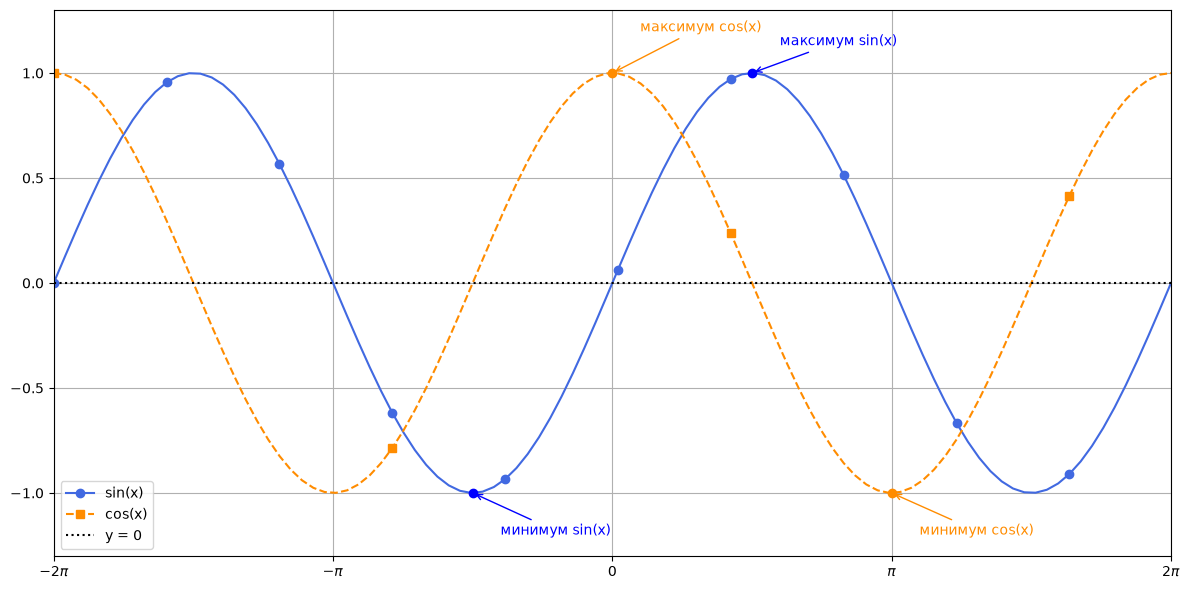

In [4]:
# Значения x на отрезке [-2π, 2π]
x = np.linspace(-2 * np.pi, 2 * np.pi, 100)

# Значения функций
y_sin = np.sin(x)
y_cos = np.cos(x)

# Создание рисунка и осей
fig, ax = plt.subplots(figsize=(12, 6))

# Построение функций
ax.plot(
    x, y_sin,
    color='royalblue',
    linestyle='-',
    marker='o',
    markevery=10,
    label='sin(x)',
)
ax.plot(
    x, y_cos,
    color='darkorange',
    linestyle='--',
    marker='s',
    markevery=30,
    label='cos(x)',
)

# Горизонтальная линия y = 0
ax.axhline(
    y = 0,
    color='black',
    linestyle=':',
    linewidth=1.5,
    label='y = 0',
)


ax.grid(True) # Сетка
ax.legend() # Легенда

# Пределы осей
ax.set_xlim(-2 * np.pi, 2 * np.pi)
ax.set_ylim(-1.3, 1.3)

# Деления оси X
ax.set_xticks([
    -2 * np.pi,
    -np.pi,
    0,
    np.pi,
    2 * np.pi,
])

# Подписи делений оси X
ax.set_xticklabels([
    r'$-2\pi$',
    r'$-\pi$',
    r'$0$',
    r'$\pi$',
    r'$2\pi$',
])

# Деления оси Y
ax.set_yticks([-1, -0.5, 0, 0.5, 1])

# Точка максимума sin(x): x = π/2, y = 1
ax.scatter(np.pi / 2, 1, color='blue', zorder=5)

ax.annotate(
    'максимум sin(x)',
    xy=(np.pi/2, 1),
    xytext=(20, 20),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='blue'),
    color='blue',
)

# Точка минимума sin(x): x = -π/2, y = -1
ax.scatter(-np.pi / 2, -1, color='blue', zorder=5)
ax.annotate(
    'минимум sin(x)',
    xy=(-np.pi / 2, -1),
    xytext=(20, -30),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='blue'),
    color='blue'
)

# Точка максимума cos(x): x = 0, y = 1
ax.scatter(0, 1, color='darkorange', zorder=5)

ax.annotate(
    'максимум cos(x)',
    xy=(0,1),
    xytext=(20, 30),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='darkorange'),
    color='darkorange',
)

# Точка минимума cos(x): x = π, y = -1
ax.scatter(np.pi, -1, color='darkorange', zorder=5)

ax.annotate(
    'минимум cos(x)',
    xy=(np.pi, -1),
    xytext=(20, -30),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='darkorange'),
    color='darkorange'
)

fig.tight_layout()

fig.savefig(
    '/Users/tgdzh/Projects/ml-engenier-course-starter/Python Base/homework/matlib/sin_cos_graph.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

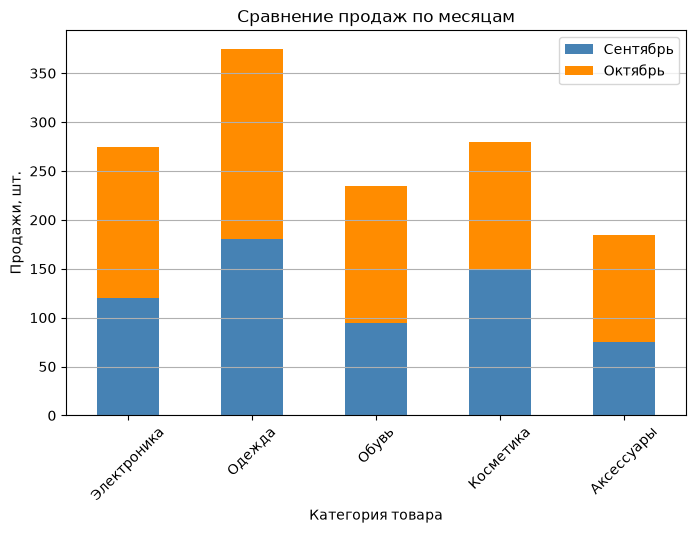

In [58]:
df = pd.DataFrame({
    "category": ["Электроника", "Одежда", "Обувь", "Косметика", "Аксессуары"],
    "september": [120, 180, 95, 150, 75],
    "october": [155, 195, 140, 130, 110]
})

fig, ax = plt.subplots(figsize=(8,5))

df.plot(
    kind='bar',
    x='category',
    y=['september', 'october'],
    color=['steelblue', 'darkorange'],
    stacked=True, # Показать общий итог и состав этого итога
    ax=ax,
)

ax.set_title('Сравнение продаж по месяцам')
ax.set_xlabel('Категория товара')
ax.set_ylabel('Продажи, шт.')
ax.grid(axis='y') # ~ ax.grid(True)
ax.legend(['Сентябрь', 'Октябрь'])
plt.xticks(rotation=45) # строка задаёт угол поворота подписей на оси X
plt.show()

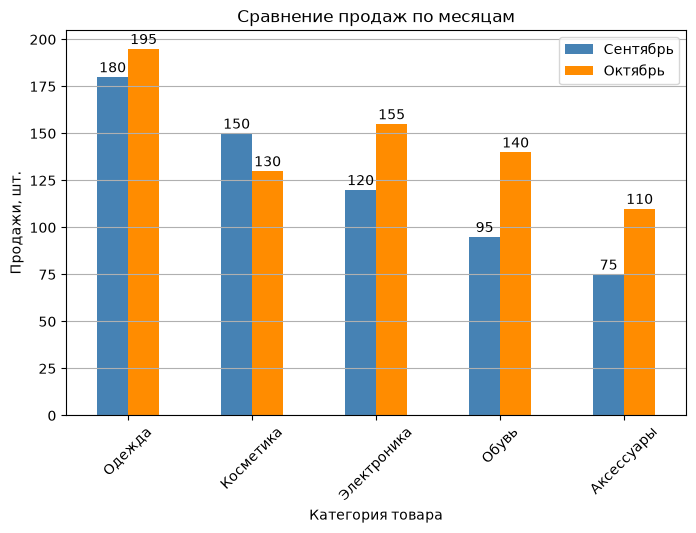

In [60]:
'''добавь числовые подписи над столбцами'''

df = pd.DataFrame({
    "category": ["Электроника", "Одежда", "Обувь", "Косметика", "Аксессуары"],
    "september": [120, 180, 95, 150, 75],
    "october": [155, 195, 140, 130, 110]
})

fig, ax = plt.subplots(figsize=(8,5))

df['total'] = df['september'] + df['october']
df_sorted = df.sort_values(
    by='total',
    ascending=False,
)
df_sorted[['category', 'september', 'october', 'total']]

df_sorted.plot(
    kind='bar',
    x='category',
    y=['september', 'october'],
    color=['steelblue', 'darkorange'],
    stacked=False, # Показать общий итог и состав этого итога
    ax=ax,
)

ax.set_title('Сравнение продаж по месяцам')
ax.set_xlabel('Категория товара')
ax.set_ylabel('Продажи, шт.')
ax.grid(axis='y') # ~ ax.grid(True)
ax.legend(['Сентябрь', 'Октябрь'])
plt.xticks(rotation=45) # строка задаёт угол поворота подписей на оси X

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%d',
        padding=1,
    )

plt.show()

,category,september,october,total
1,Одежда,180,195,375
3,Косметика,150,130,280
0,Электроника,120,155,275
2,Обувь,95,140,235
4,Аксессуары,75,110,185


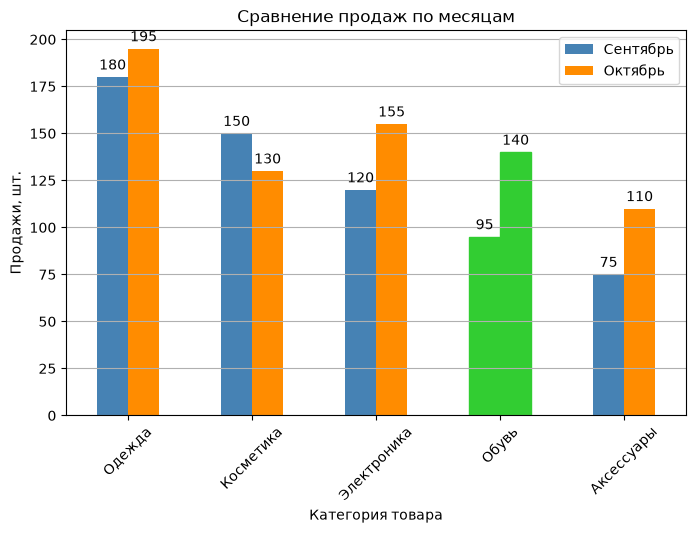

In [67]:
'''выдели цветом категорию с максимальным ростом'''

df = pd.DataFrame({
    "category": ["Электроника", "Одежда", "Обувь", "Косметика", "Аксессуары"],
    "september": [120, 180, 95, 150, 75],
    "october": [155, 195, 140, 130, 110]
})

fig, ax = plt.subplots(figsize=(8,5))

df['total'] = df['september'] + df['october']
df_sorted = df.sort_values(
    by='total',
    ascending=False,
)
display(df_sorted[['category', 'september', 'october', 'total']])

df_sorted.plot(
    kind='bar',
    x='category',
    y=['september', 'october'],
    color=['steelblue', 'darkorange'],
    stacked=False, # Показать общий итог и состав этого итога
    ax=ax,
)

ax.set_title('Сравнение продаж по месяцам')
ax.set_xlabel('Категория товара')
ax.set_ylabel('Продажи, шт.')
ax.grid(axis='y') # ~ ax.grid(True)
ax.legend(['Сентябрь', 'Октябрь'])
plt.xticks(rotation=45) # строка задаёт угол поворота подписей на оси X

df_sorted['growth'] = (
    df_sorted['october'] - df_sorted['september']
)
max_growth_category = df_sorted.loc[
    df_sorted['growth'].idxmax(),
    'category'
]

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
    
    for i, bar in enumerate(container):
        category = df_sorted.iloc[i]['category']

        if category == max_growth_category:
              bar.set_color('limegreen')

plt.show()

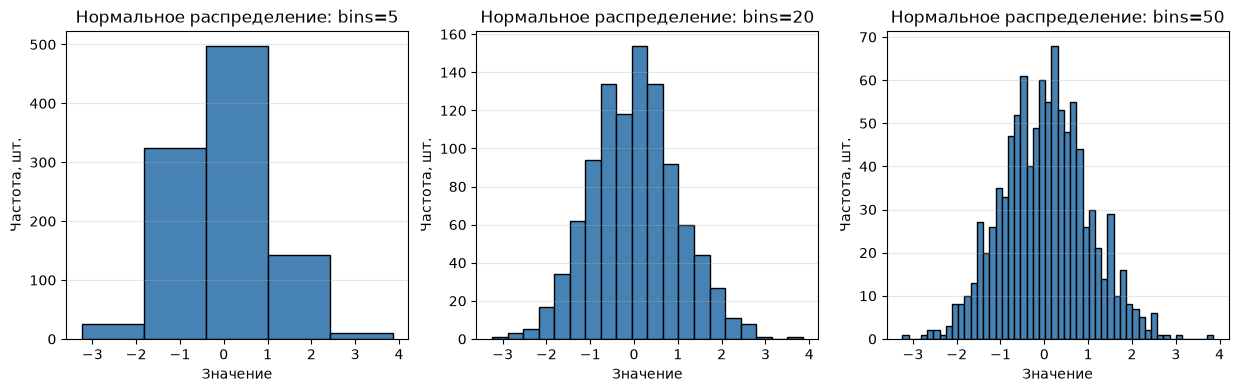

In [72]:
'''3. Распределения и выбросы'''

# Сгенерируй три выборки с разными распределениями.
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42) # Чтобы результаты можно было воспроизводить

# Нормальное распределение
normal_data = np.random.normal(
    loc=0, # среднее значение распределения ~ центр распределения
    scale=1, # стандартное отклонение ~ разброс значений
    size=1000, # количество случайных значений ~ размер выборки
) 

# Равномерное распределение
uniform_data = np.random.uniform(
    low=-3,
    high=3,
    size=1000,
)

# Экспоненциальное распределение
exponential_data = np.random.exponential(
    scale=1,
    size=1000,
)

'''построй гистограммы с разным количеством bins и сравни результат'''
fix, axes = plt.subplots(1, 3, figsize=(15,4)) # 1 – кол-во строк графиков, 3 – кол-во столбцов графиков
bins_values = [5, 20, 50]

for ax, bins in zip(axes, bins_values):
    ax.hist(
        normal_data,
        bins=bins,
        color='steelblue',
        edgecolor='black',
    )

    ax.set_title(f'Нормальное распределение: bins={bins}')
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота, шт.')
    ax.grid(axis='y', alpha=0.3) # alpha задает прозрачность элемента графика

fig.tight_layout() # Автоматически настраивает отступы между графиками, заголовками и подписями осей
plt.show()

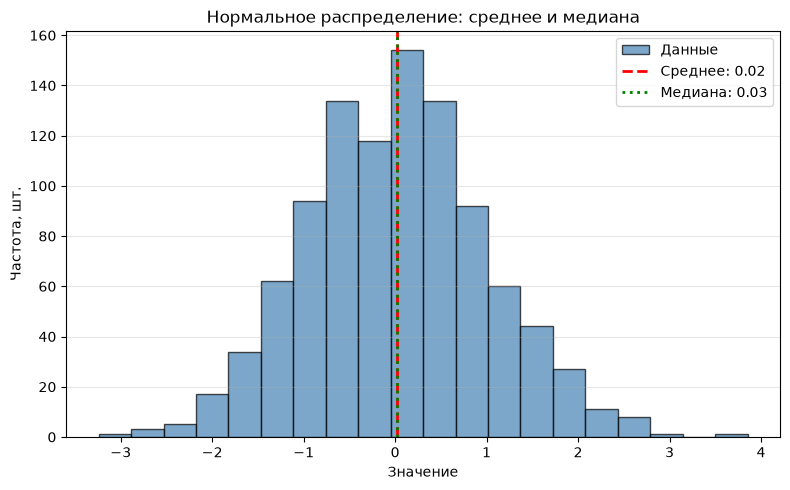

In [82]:
fig, ax = plt.subplots(figsize=(8, 5))

# Гистограмма
ax.hist(
    normal_data,
    bins=20,
    color='steelblue',
    edgecolor='black',
    alpha=0.7,
    label='Данные'
)

# Среднее и медиана
mean_value = np.mean(normal_data)
median_value = np.median(normal_data)

# Вертикальная линия среднего
ax.axvline(
    mean_value, 
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Среднее: {mean_value:.2f}',
)

# Вертикальная линия медианы
ax.axvline(
    median_value,
    color='green',
    linestyle=':',
    linewidth=2,
    label=f'Медиана: {median_value:.2f}',
)

ax.set_title('Нормальное распределение: среднее и медиана')
ax.set_xlabel('Значение')
ax.set_ylabel('Частота, шт.')
ax.grid(axis='y', alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

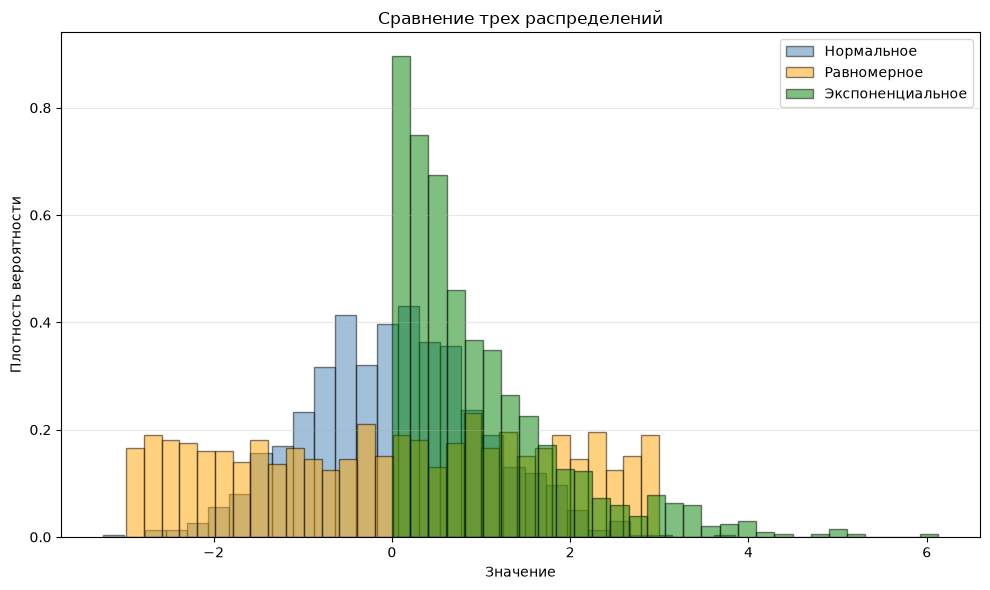

In [84]:
'''сравнить три распределения на одном графике с прозрачностью alpha.'''
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    normal_data,
    bins=30,
    density=True, # Переводит гистограмму из количества наблюдений в плотность распределения
    alpha=0.5,
    color='steelblue',
    edgecolor='black', # Задаёт цвет границы каждого столбца гистограммы
    label='Нормальное',
)

ax.hist(
    uniform_data,
    bins=30,
    density=True,
    alpha=0.5,
    color='orange',
    edgecolor='black',
    label='Равномерное',
)

ax.hist(
    exponential_data,
    bins=30,
    density=True,
    alpha=0.5,
    color='green',
    edgecolor='black',
    label='Экспоненциальное'
)

ax.set_title('Сравнение трех распределений')
ax.set_xlabel('Значение')
ax.set_ylabel('Плотность вероятности')
ax.grid(axis='y', alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

'''Вывод
- нормальное распределение симметрично относительно нуля, 
- равномерное распределение имеет примерно одинаковую плотность на заданном интервале,
- экспоненциальное распределение смещено вправо и имеет длинный правый хвост. 
- Прозрачность `alpha` позволяет увидеть области перекрытия распределений.
- По вертикальной оси указана плотность вероятности, а не количество объектов, поскольку использован параметр density=True.
- Перекрывающиеся цветные области показывают диапазоны, где разные распределения принимают похожие значения.
'''

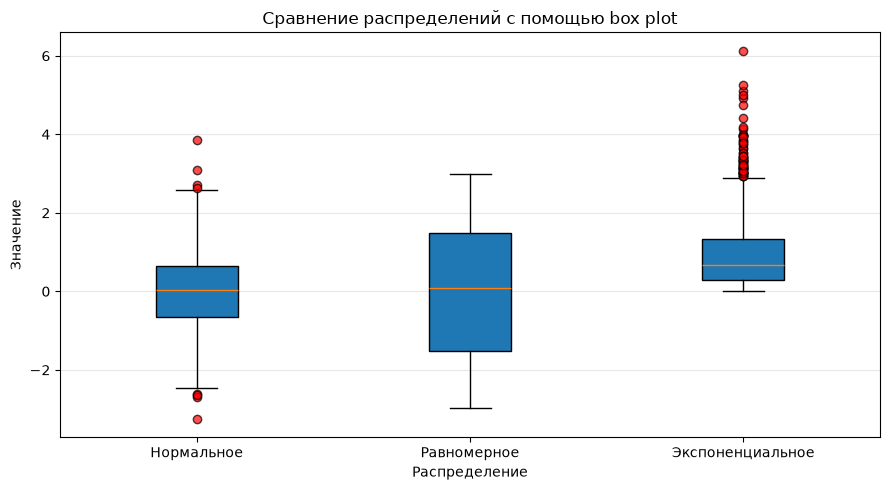

In [90]:
'''построй box plot и отметь выбросы'''
fig, ax = plt.subplots(figsize=(9, 5))

box_plot = ax.boxplot(
    [
        normal_data,
        uniform_data,
        exponential_data,
    ],
    tick_labels=[
        'Нормальное',
        'Равномерное',
        'Экспоненциальное',
    ],
    patch_artist=True, # Позволяет закрашивать внутреннюю область коробок. Без него коробки обычно только контурные.
    showfliers=True, # Показывает выбросы на графике.
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'red',
        'markeredgecolor': 'black',
        'markersize': 6,
        'alpha': 0.7,
    },
)

ax.set_title('Сравнение распределений с помощью box plot')
ax.set_xlabel('Распределение')
ax.set_ylabel('Значение')
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

'''Выводы
- нормальное распределение примерно симметрично и сосредоточено около нуля. 
- Равномерное распределение имеет широкий и относительно равномерный разброс без выраженных выбросов. 
- Экспоненциальное распределение смещено вправо: большинство значений небольшие, но присутствует длинный правый хвост и много верхних выбросов. 
Выбросы в данном случае не обязательно являются ошибками — для экспоненциального распределения они могут быть естественной особенностью распределения.
'''

In [ ]:
'''построй violin plot и сравни его информативность с box plot'''

fix, ax = plt.subplots(figsize=(9,5))

violin = ax.violinplot(
    [
        normal_data,
        uniform_data,
        exponential_data,
    ],
    showmeans=True,
    showmedians=True,
    showextrema=True,
)

ax.set_title('Сравнение распределений с помощью violin plot')
ax.set_xlabel('Распределение')
ax.set_ylabel('Значение')
ax.set_xticks([1, 2, 3])
ax.set_xticklabels([
    'Нормальное',
    'Равномерное',
    'Экспоненциальное'
])
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

'''Вывод
- violin plot позволяет сравнить не только медианы и диапазоны распределений, но и плотность значений. 
- Нормальное распределение симметрично относительно нуля, 
- равномерное занимает широкий диапазон, 
- экспоненциальное сосредоточено около малых положительных значений и имеет длинный правый хвост. 
=> Поэтому violin plot информативнее box plot при анализе формы распределения, однако для явного отображения выбросов box plot удобнее.
'''

In [ ]:
'''объясни, почему внешний вид гистограммы зависит от выбора количества интервалов

Внешний вид гистограммы зависит от количества интервалов, потому что bins определяет степень детализации группировки данных. 
Малое количество интервалов сглаживает распределение и может скрыть его особенности.
Большое количество интервалов делает график более подробным, но одновременно усиливает влияние случайного шума. 
Поэтому количество bins нужно выбирать так, чтобы были видны основные свойства распределения без лишней детализации.
'''

# 4. Связь между признаками

In [100]:
'''Сгенерируй признаки x, y, категорию объекта и числовой показатель размера.'''

'''
что нужно знать о каждом объекте, чтобы потом нарисовать его на графике? У каждой точки будет четыре характеристики: 
- координата по горизонтали x, 
- координата по вертикали y, 
- категория для цвета
- числовой показатель для размера.
'''
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 150

# Признак x
x = np.random.normal(
    loc=0,
    scale=2,
    size=n
)

# Признак y с примерно линейной зависимостью от x
y = 2 * x + np.random.normal(
    loc=0,
    scale=2,
    size=n
)

# Категория каждого объекта
category = np.random.choice(
    ['A', 'B', 'C'],
    size=n
)

# Числовой показатель, который позже задаст размер точки
size_value = np.random.uniform(
    low=20,
    high=200,
    size=n
)